In [ ]:
# Gerekli kütüphaneyi içe aktar
import pandas as pd

# Dosyalar doğrudan Colab ortamına yüklendiği için '/content/' dizinini kullanıyoruz
path = '/content/'

# 1. Ana Verileri Yükle (İlk 4 satırı atlayarak)
df_gdp = pd.read_csv(path + 'API_NY.GDP.PCAP.KD_DS2_en_csv_v2_4863.csv', skiprows=4)
df_co2 = pd.read_csv(path + 'API_EN.GHG.CO2.PC.CE.AR5_DS2_en_csv_v2_272.csv', skiprows=4)
df_renew = pd.read_csv(path + 'API_EG.FEC.RNEW.ZS_DS2_en_csv_v2_11.csv', skiprows=4)
df_rnd = pd.read_csv(path + 'API_GB.XPD.RSDV.GD.ZS_DS2_en_csv_v2_5013.csv', skiprows=4)

# 2. Ülke Metadata Verisini Yükle (Bunda skiprows'a gerek yok)
df_meta = pd.read_csv(path + 'Metadata_Country_API_EG.FEC.RNEW.ZS_DS2_en_csv_v2_11.csv')

print("Bütün veriler başarıyla DataFrame'lere aktarıldı!")

Bütün veriler başarıyla DataFrame'lere aktarıldı!


In [ ]:
# Verileri temizlemek ve yılları satırlara indirmek (melt) için bir fonksiyon yazalım
def temizle_ve_erit(df, deger_ismi):
    # Dünya bankası verilerinde en sonda genelde içi boş 'Unnamed: 67' gibi bir sütun olur, onu temizleyelim
    df = df.loc[:, ~df.columns.str.contains('^Unnamed')]

    # Modele sokmayacağımız gereksiz etiket sütunlarını atalım
    silinecek_sutunlar = ['Country Code', 'Indicator Name', 'Indicator Code']
    df = df.drop(columns=silinecek_sutunlar, errors='ignore')

    # Melt işlemi: Yılları sütun olmaktan çıkarıp 'Year' adında tek bir sütuna topluyoruz
    df_melted = df.melt(id_vars=['Country Name'], var_name='Year', value_name=deger_ismi)

    # Yıl sütununu tam sayıya (integer) çevirelim (Örn: "2020" -> 2020)
    df_melted['Year'] = df_melted['Year'].astype(int)

    return df_melted

# 4 ana verimize de bu fonksiyonu uygulayalım
df_gdp_temiz = temizle_ve_erit(df_gdp, 'GDP_Per_Capita')
df_co2_temiz = temizle_ve_erit(df_co2, 'CO2_Emissions')
df_renew_temiz = temizle_ve_erit(df_renew, 'Renewable_Energy')
df_rnd_temiz = temizle_ve_erit(df_rnd, 'RnD_Expenditure')

# Nasıl göründüğüne bakalım
print("Dönüşüm başarılı! GSYİH verisinin ilk 5 satırı:")
print(df_gdp_temiz.head())

Dönüşüm başarılı! GSYİH verisinin ilk 5 satırı:
                  Country Name  Year  GDP_Per_Capita
0                        Aruba  1960             NaN
1  Africa Eastern and Southern  1960     1186.271645
2                  Afghanistan  1960             NaN
3   Africa Western and Central  1960     1130.438388
4                       Angola  1960             NaN


In [ ]:
from functools import reduce

# 1. Dört ana veriyi Country Name ve Year üzerinden yan yana birleştiriyoruz
tablolar = [df_gdp_temiz, df_co2_temiz, df_renew_temiz, df_rnd_temiz]
df_master = reduce(lambda sol, sag: pd.merge(sol, sag, on=['Country Name', 'Year'], how='outer'), tablolar)

# 2. Ülke metadata tablosundan sadece işimize yarayan kısımları alalım
# Dünya Bankası metadata dosyasında asıl ülke adları genelde 'TableName' sütununda yer alır
df_meta_temiz = df_meta[['TableName', 'Region', 'IncomeGroup']].rename(columns={'TableName': 'Country Name'})

# 3. Ana tablomuz ile ülke bilgilerini (kıta ve gelir durumu) eşleştiriyoruz
df_final = pd.merge(df_master, df_meta_temiz, on='Country Name', how='left')

# 4. Gerçek ülkeleri ayıklama operasyonu
# Region sütunu boş (NaN) olanlar ülke değil, bölgesel gruplardır (Dünya, Avrupa Birliği vs.). Onları siliyoruz.
df_final = df_final.dropna(subset=['Region'])

# Analizimiz için çok eski yıllarda veri kalitesi düşük olduğu için,
# milenyum sonrası döneme odaklanalım (2000 yılı ve sonrası)
df_final = df_final[df_final['Year'] >= 2000]

print("Birleştirme operasyonu başarılı! Tablonun boyutu (Satır, Sütun):", df_final.shape)
print("\nVerinin son hali:")
print(df_final.head())

Birleştirme operasyonu başarılı! Tablonun boyutu (Satır, Sütun): (5512, 8)

Verinin son hali:
   Country Name  Year  GDP_Per_Capita  CO2_Emissions  Renewable_Energy  \
40  Afghanistan  2000      308.318270       0.050138              45.0   
41  Afghanistan  2001      277.118051       0.046351              45.6   
42  Afghanistan  2002      338.139974       0.043914              37.8   
43  Afghanistan  2003      346.071627       0.044745              36.7   
44  Afghanistan  2004      338.637274       0.038301              44.2   

    RnD_Expenditure                      Region IncomeGroup  
40              NaN  Middle East & North Africa  Low income  
41              NaN  Middle East & North Africa  Low income  
42              NaN  Middle East & North Africa  Low income  
43              NaN  Middle East & North Africa  Low income  
44              NaN  Middle East & North Africa  Low income  


In [ ]:
# Üzerinde çalışacağımız sayısal sütunları seçiyoruz
sayisal_sutunlar = ['GDP_Per_Capita', 'CO2_Emissions', 'Renewable_Energy', 'RnD_Expenditure']

# 1. AŞAMA: Ülke içi doldurma (Enterpolasyon + İleri/Geri Doldurma)
# Her ülkeyi kendi içinde gruplayıp, boşlukları mantıklı bir çizgiyle (linear) dolduruyoruz
for sutun in sayisal_sutunlar:
    df_final[sutun] = df_final.groupby('Country Name')[sutun].transform(
        lambda x: x.interpolate(method='linear').bfill().ffill()
    )

# 2. AŞAMA: Kıta bazlı doldurma
# Eğer ülke tarihinde o veriyi hiç açıklamadıysa, o ülkenin eksiklerini bulunduğu kıtanın ortalaması ile dolduruyoruz
for sutun in sayisal_sutunlar:
    df_final[sutun] = df_final[sutun].fillna(df_final.groupby('Region')[sutun].transform('mean'))

# 3. Sonuç Kontrolü
print("Doldurma operasyonu sonrası eksik veri (NaN) sayıları:")
print(df_final.isnull().sum())
print("\nAfganistan'ın güncel durumu:")
print(df_final[df_final['Country Name'] == 'Afghanistan'].head())

Doldurma operasyonu sonrası eksik veri (NaN) sayıları:
Country Name        0
Year                0
GDP_Per_Capita      0
CO2_Emissions       0
Renewable_Energy    0
RnD_Expenditure     0
Region              0
IncomeGroup         0
dtype: int64

Afganistan'ın güncel durumu:
   Country Name  Year  GDP_Per_Capita  CO2_Emissions  Renewable_Energy  \
40  Afghanistan  2000      308.318270       0.050138              45.0   
41  Afghanistan  2001      277.118051       0.046351              45.6   
42  Afghanistan  2002      338.139974       0.043914              37.8   
43  Afghanistan  2003      346.071627       0.044745              36.7   
44  Afghanistan  2004      338.637274       0.038301              44.2   

    RnD_Expenditure                      Region IncomeGroup  
40         0.631714  Middle East & North Africa  Low income  
41         0.631714  Middle East & North Africa  Low income  
42         0.631714  Middle East & North Africa  Low income  
43         0.631714  Middle East 

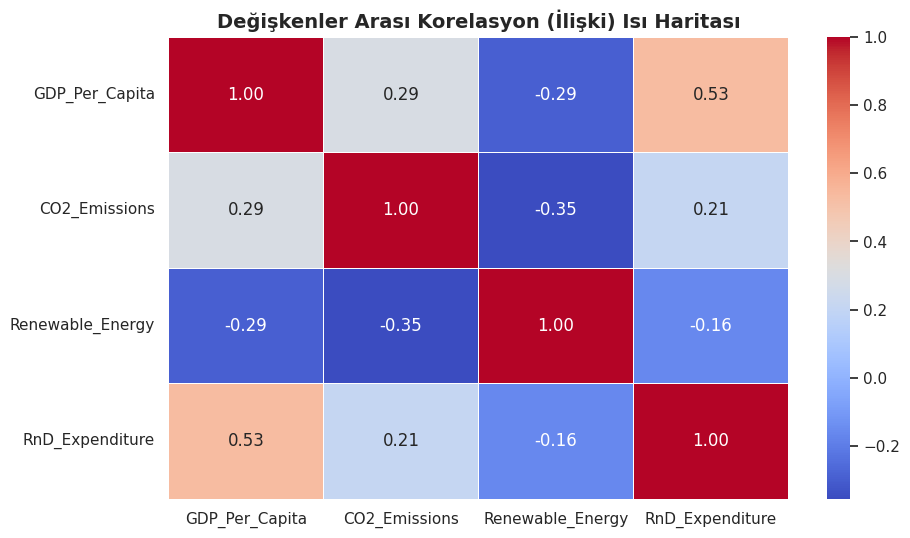


--------------------------------------------------



In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Grafiklerin genel stilini ve boyutlarını ayarlayalım
sns.set_theme(style="whitegrid")

# ==========================================
# 1. KORELASYON ISI HARİTASI (Heatmap)
# ==========================================
plt.figure(figsize=(10, 6))
# Sadece sayısal olan 4 kolonumuzu seçip korelasyon matrisini hesaplıyoruz
sayisal_veriler = df_final[['GDP_Per_Capita', 'CO2_Emissions', 'Renewable_Energy', 'RnD_Expenditure']]
korelasyon_matrisi = sayisal_veriler.corr()

# Isı haritasını çizdiriyoruz
sns.heatmap(korelasyon_matrisi, annot=True, cmap="coolwarm", fmt=".2f", linewidths=0.5)
plt.title("Değişkenler Arası Korelasyon (İlişki) Isı Haritası", fontsize=14, fontweight='bold')
plt.show()

print("\n" + "-"*50 + "\n")



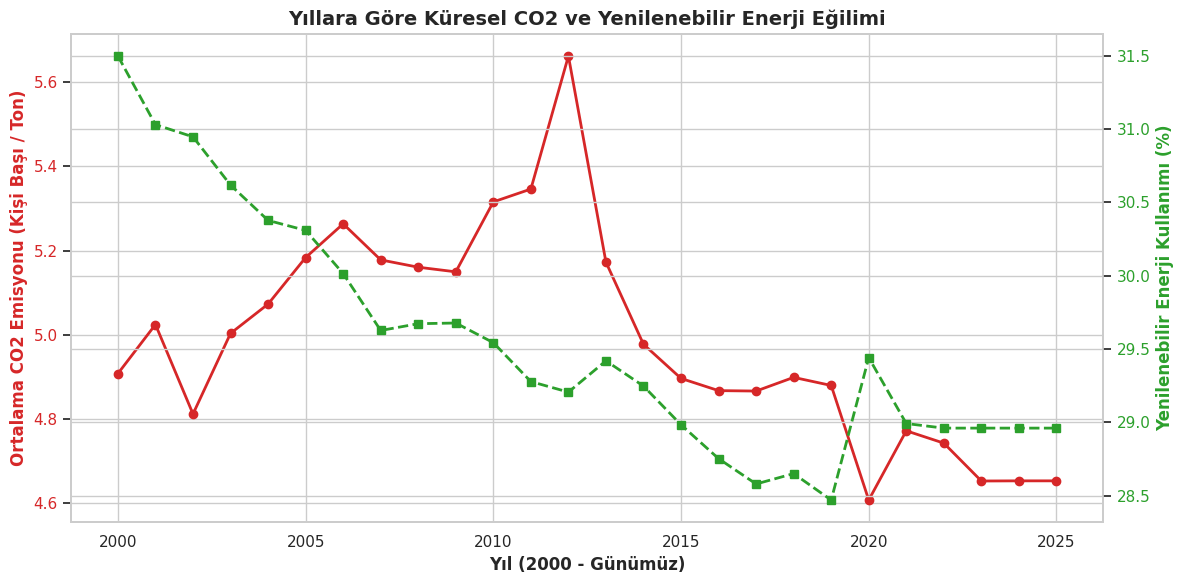

In [ ]:
# 2. YILLARA GÖRE KÜRESEL TREND GRAFİĞİ
# Dünya genelindeki eğilimi görmek için yılları gruplayıp ortalamalarını alıyoruz
df_trend = df_final.groupby('Year')[['CO2_Emissions', 'Renewable_Energy']].mean().reset_index()

# İki farklı birimi (Ton ve Yüzde) aynı grafikte göstermek için çift Y eksenli (twinx) grafik kuruyoruz
fig, ax1 = plt.subplots(figsize=(12, 6))

# Sol Y Ekseni: CO2 Emisyonları (Kırmızı renk)
color1 = 'tab:red'
ax1.set_xlabel('Yıl (2000 - Günümüz)', fontsize=12, fontweight='bold')
ax1.set_ylabel('Ortalama CO2 Emisyonu (Kişi Başı / Ton)', color=color1, fontsize=12, fontweight='bold')
ax1.plot(df_trend['Year'], df_trend['CO2_Emissions'], color=color1, marker='o', linewidth=2, label='CO2 Emisyonu')
ax1.tick_params(axis='y', labelcolor=color1)

# Sağ Y Ekseni: Yenilenebilir Enerji (Yeşil renk)
ax2 = ax1.twinx()
color2 = 'tab:green'
ax2.set_ylabel('Yenilenebilir Enerji Kullanımı (%)', color=color2, fontsize=12, fontweight='bold')
ax2.plot(df_trend['Year'], df_trend['Renewable_Energy'], color=color2, marker='s', linestyle='dashed', linewidth=2, label='Yenilenebilir Enerji')
ax2.tick_params(axis='y', labelcolor=color2)

plt.title("Yıllara Göre Küresel CO2 ve Yenilenebilir Enerji Eğilimi", fontsize=14, fontweight='bold')
fig.tight_layout()
plt.show()

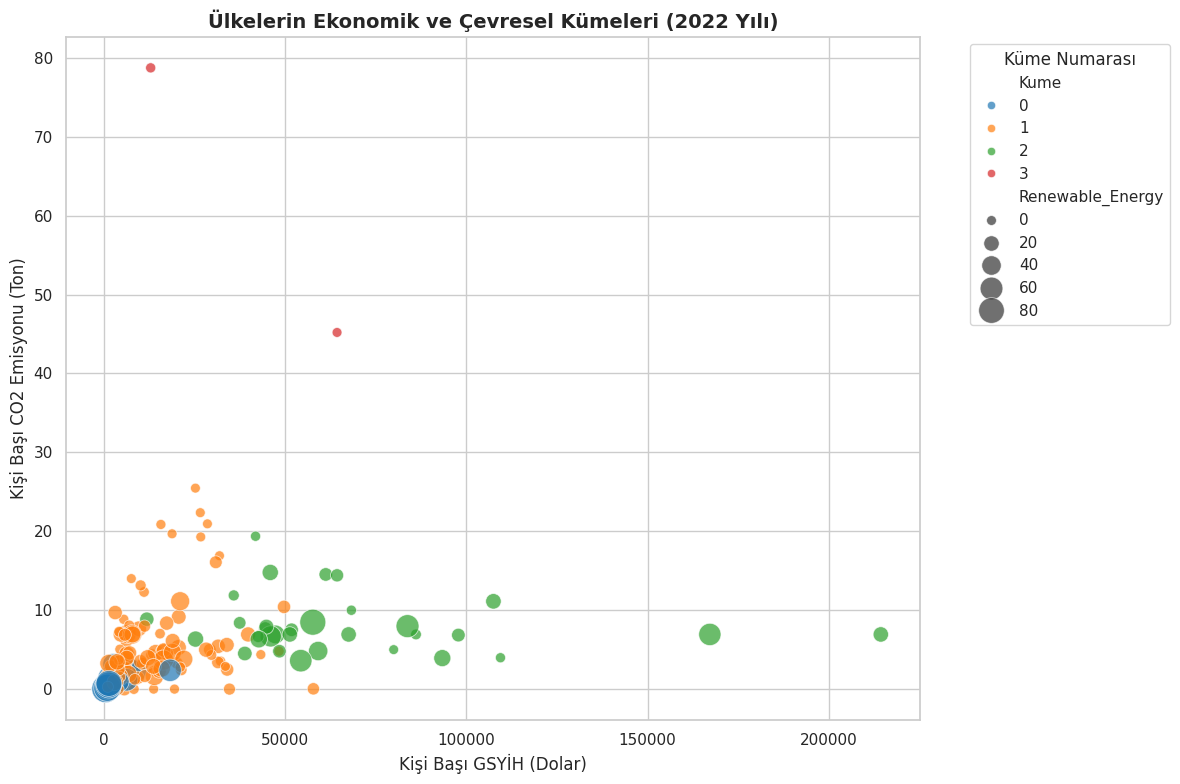


--- Yapa Zekanın Bulduğu 4 Ülke Kümesinin Özellikleri ---
      GDP_Per_Capita  CO2_Emissions  Renewable_Energy  RnD_Expenditure  \
Kume                                                                     
0            2191.68           0.68             68.05             0.29   
1           12849.14           4.70             14.55             0.54   
2           66502.08           8.06             22.30             2.41   
3           38602.62          61.96              0.45             0.77   

      Ulke_Sayisi  
Kume               
0              53  
1             125  
2              32  
3               2  


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# 1. Analizi güncel tutmak için veri setindeki en son yıla (veya 2022'ye) filtre atalım
en_son_yil = df_final['Year'].max()
df_guncel = df_final[df_final['Year'] == 2022].copy() # 2022 verileri genelde daha eksiksizdir

# 2. Modele sokacağımız 4 sayısal sütunu seçiyoruz
ozellikler = ['GDP_Per_Capita', 'CO2_Emissions', 'Renewable_Energy', 'RnD_Expenditure']
X = df_guncel[ozellikler]

# 3. VERİ ÖLÇEKLENDİRME (Standardization - Çok Kritik!)
scaler = StandardScaler()
X_olcekli = scaler.fit_transform(X)

# 4. K-MEANS MODELİ KURULUMU
# Ülkeleri 4 farklı karakter grubuna ayırmasını istiyoruz
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
df_guncel['Kume'] = kmeans.fit_predict(X_olcekli)

# 5. GÖRSELLEŞTİRME: Ülkelerin Dağılım Haritası
plt.figure(figsize=(12, 8))
sns.scatterplot(
    x='GDP_Per_Capita',
    y='CO2_Emissions',
    hue='Kume',
    palette='tab10',
    size='Renewable_Energy',
    sizes=(50, 400), # Yenilenebilir enerji kullanan ülkelerin noktaları daha büyük olacak
    alpha=0.7,
    data=df_guncel
)

plt.title("Ülkelerin Ekonomik ve Çevresel Kümeleri (2022 Yılı)", fontsize=14, fontweight='bold')
plt.xlabel("Kişi Başı GSYİH (Dolar)")
plt.ylabel("Kişi Başı CO2 Emisyonu (Ton)")
plt.legend(title='Küme Numarası', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

# 6. Kümelerin Karakter Analizi (Ortalamaları alıyoruz)
kume_ozet = df_guncel.groupby('Kume')[ozellikler].mean().round(2)
kume_boyutlari = df_guncel.groupby('Kume').size().rename("Ulke_Sayisi")
kume_sonuc = pd.concat([kume_ozet, kume_boyutlari], axis=1)

print("\n--- Yapa Zekanın Bulduğu 4 Ülke Kümesinin Özellikleri ---")
print(kume_sonuc)

/tmp/ipykernel_1470/409182353.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rf_model.feature_importances_, y=X_rf.columns, palette='viridis')


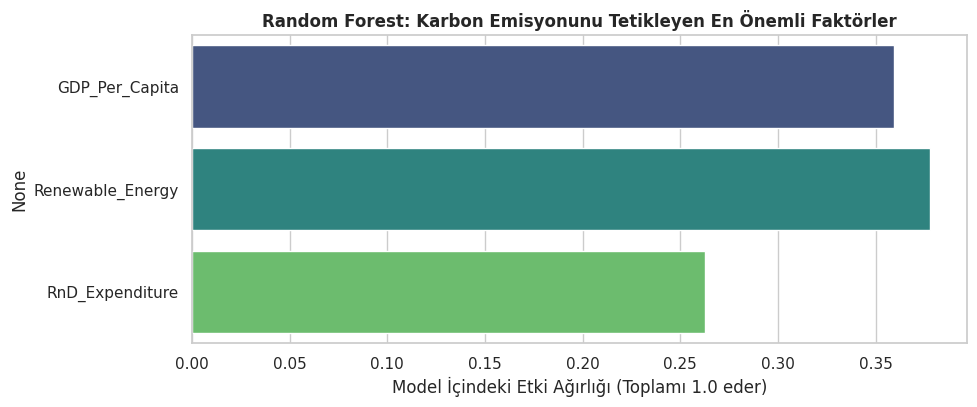

In [ ]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt
import seaborn as sns

# Tahmin edilecek hedef (y) CO2, tahmin edecek özellikler (X) ise diğer 3 değişken
X_rf = df_guncel[['GDP_Per_Capita', 'Renewable_Energy', 'RnD_Expenditure']]
y_rf = df_guncel['CO2_Emissions']

# Modeli kurup eğitiyoruz
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_rf, y_rf)

# Yapay zekanın özelliklere verdiği önem ağırlıklarını görselleştiriyoruz
plt.figure(figsize=(10, 4))
sns.barplot(x=rf_model.feature_importances_, y=X_rf.columns, palette='viridis')
plt.title("Random Forest: Karbon Emisyonunu Tetikleyen En Önemli Faktörler", fontsize=12, fontweight='bold')
plt.xlabel("Model İçindeki Etki Ağırlığı (Toplamı 1.0 eder)")
plt.show()

In [ ]:
from sklearn.ensemble import IsolationForest

# Modelin, verinin %5'ini anormal (outlier) olarak bulmasını istiyoruz
iso_forest = IsolationForest(contamination=0.05, random_state=42)

# Modeli daha önce K-Means için hazırladığımız ölçeklendirilmiş veri (X_olcekli) ile eğitiyoruz
# 1 dönenler NORMAL, -1 dönenler ANORMAL (Outlier) demektir
df_guncel['Anormallik_Durumu'] = iso_forest.fit_predict(X_olcekli)

# Sadece anormal (-1) tespit edilen ülkeleri filtreleyip ekrana yazdırıyoruz
df_anormal = df_guncel[df_guncel['Anormallik_Durumu'] == -1]

print("--- Isolation Forest Tarafından Tespit Edilen 'Anormal' Ülkeler ---")
print(df_anormal[['Country Name', 'GDP_Per_Capita', 'CO2_Emissions', 'Renewable_Energy', 'Kume']])

--- Isolation Forest Tarafından Tespit Edilen 'Anormal' Ülkeler ---
        Country Name  GDP_Per_Capita  CO2_Emissions  Renewable_Energy  Kume
7322         Iceland    57626.253372       8.480038         82.400000     2
7784          Israel    42539.274877       6.658268          6.200000     2
8378     Korea, Rep.    35809.013811      11.873741          3.600000     2
9368   Liechtenstein   167187.157310       6.928856         56.900000     2
9698      Luxembourg   107467.123965      11.124891         20.500000     2
10886         Monaco   214359.505135       6.928856         19.876052     2
12074         Norway    83756.738381       7.979858         61.400000     2
12536          Palau    12889.621606      78.726280          0.900000     3
13262          Qatar    64315.626364      45.195954          0.000000     3
15506         Sweden    54304.187750       3.599963         57.900000     2
16760  United States    64322.233282      14.418622         10.900000     2


INFO:prophet:n_changepoints greater than number of observations. Using 19.


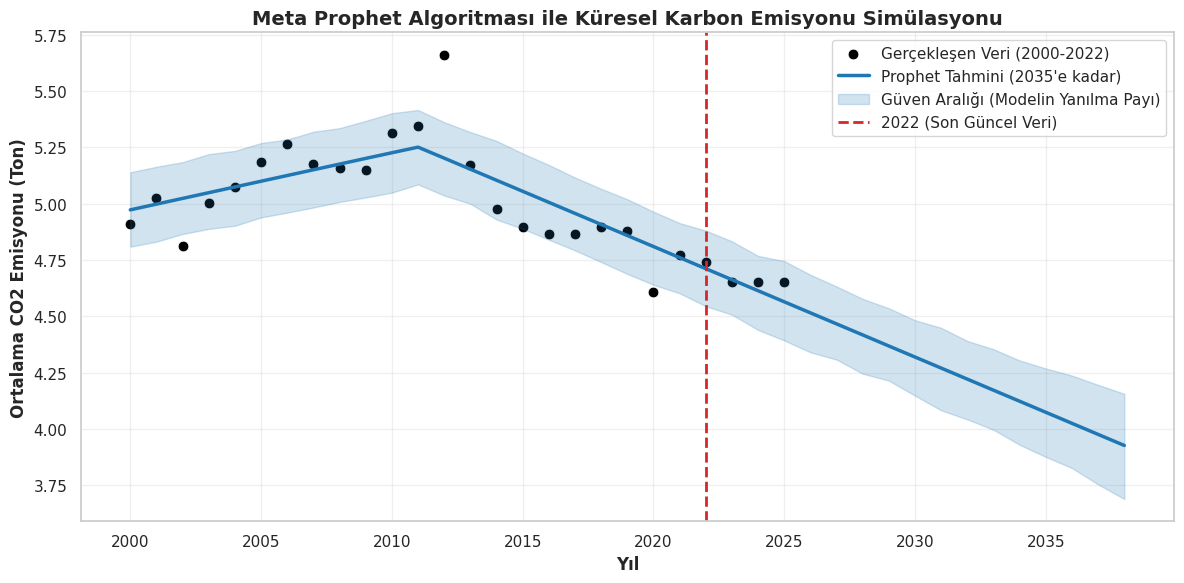

In [ ]:
from prophet import Prophet
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ==========================================
# 4. YENİ NESİL GELECEK TAHMİNİ (Meta Prophet)
# ==========================================

# 1. Prophet için veriyi hazırlama
# Prophet algoritması zaman sütununun adını 'ds', değerin adını 'y' olarak ister
df_prophet = df_gecmis[['Year', 'CO2_Emissions']].copy()

# Yılları Prophet'in anlayacağı tarih formatına (Örn: 2000 -> 2000-01-01) çeviriyoruz
df_prophet['ds'] = pd.to_datetime(df_prophet['Year'], format='%Y')
df_prophet['y'] = df_prophet['CO2_Emissions']

# 2. Modeli Kurma ve Eğitme
# Yıllık makroekonomik veri olduğu için günlük/haftalık mevsimselliği kapatıyoruz
model_prophet = Prophet(yearly_seasonality=False, weekly_seasonality=False, daily_seasonality=False)
model_prophet.fit(df_prophet)

# 3. Geleceği Simüle Etme (2023 - 2035 arası 13 yıl)
gelecek_adımlar = model_prophet.make_future_dataframe(periods=13, freq='YS') # YS = Yılın Başı
tahminler = model_prophet.predict(gelecek_adımlar)

# 4. Görselleştirme
plt.figure(figsize=(12, 6))

# Gerçek Veriler (Siyah Noktalar)
sns.scatterplot(x=df_prophet['ds'].dt.year, y=df_prophet['y'], color='black', s=60, label='Gerçekleşen Veri (2000-2022)')

# Prophet Tahmin Çizgisi (Mavi Çizgi)
sns.lineplot(x=tahminler['ds'].dt.year, y=tahminler['yhat'], color='tab:blue', linewidth=2.5, label='Prophet Tahmini (2035\'e kadar)')

# Güven Aralığı (Gölgeli Alan)
plt.fill_between(tahminler['ds'].dt.year, tahminler['yhat_lower'], tahminler['yhat_upper'], color='tab:blue', alpha=0.2, label='Güven Aralığı (Modelin Yanılma Payı)')

# 2022 Yılı Çizgisi
plt.axvline(x=2022, color='tab:red', linestyle='--', label='2022 (Son Güncel Veri)', linewidth=2)

plt.title("Meta Prophet Algoritması ile Küresel Karbon Emisyonu Simülasyonu", fontsize=14, fontweight='bold')
plt.xlabel("Yıl", fontsize=12, fontweight='bold')
plt.ylabel("Ortalama CO2 Emisyonu (Ton)", fontsize=12, fontweight='bold')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Tüm bu analizli veriyi Power BI'da kullanmak üzere yerel çalışma ortamına kaydedelim
df_guncel.to_csv('/content/KMeans_Sonuclari_2022.csv', index=False)
print("Veri yerel diske (Power BI için) başarıyla kaydedildi! Sol menüden bilgisayarınıza indirebilirsiniz.")

Veri yerel diske (Power BI için) başarıyla kaydedildi! Sol menüden bilgisayarınıza indirebilirsiniz.
